# NIM   : 11322004
# Nama  : Destina Manurung
# Prodi : D3 Teknologi Informasi 2022

# SOAL 1

## a. Deteksi missing value dan outlier.

In [1]:
# Missing Value

import pandas as pd
path = "clv_data.csv"
df = pd.read_csv(path)
df

,Unnamed: 0,id,age,gender,income,days_on_platform,city,purchases
0,0,0,NaN,Male,126895,14.0,San Francisco,0
1,1,1,NaN,Male,161474,14.0,Tokyo,0
2,2,2,24.0,Male,104723,34.0,London,1
3,3,3,29.0,Male,43791,28.0,London,2
4,4,4,18.0,Female,132181,26.0,London,2
...,...,...,...,...,...,...,...,...
4995,4995,4995,NaN,Female,212261,28.0,San Francisco,1
4996,4996,4996,NaN,Male,70228,12.0,San Francisco,0
4997,4997,4997,NaN,Male,64995,14.0,New York City,0
4998,4998,4998,NaN,Male,56144,4.0,New York City,2


In [3]:
# Menghitung data yang hilang

df.isnull().sum()

Unnamed: 0             0
id                     0
age                 2446
gender                 0
income                 0
days_on_platform     141
city                   0
purchases              0
dtype: int64

## b. Imputasi missing value menggunakan mean atau median. Jelaskan alasan pemilihan mean/median

In [4]:
df.describe()

,Unnamed: 0,id,age,income,days_on_platform,purchases
count,5000.000000,5000.000000,2554.000000,5000.000000,4859.000000,5000.000000
mean,2499.500000,2499.500000,30.202036,79593.336200,24.389998,1.101000
std,1443.520003,1443.520003,12.129439,60304.056095,18.153388,1.181473
min,0.000000,0.000000,10.000000,4.000000,1.000000,0.000000
25%,1249.750000,1249.750000,19.000000,32752.500000,10.000000,0.000000
50%,2499.500000,2499.500000,30.000000,65989.000000,21.000000,1.000000
75%,3749.250000,3749.250000,41.000000,115406.500000,35.000000,2.000000
max,4999.000000,4999.000000,50.000000,388572.000000,111.000000,6.000000


## c. Tampilkan presentase missing value sebelum dan sesudah handling missing value

### Menghitung persentasi data yang hilang sebelum handling missing value

In [5]:
percent_missing = 100*df.isnull().mean()
percent_missing

Unnamed: 0           0.00
id                   0.00
age                 48.92
gender               0.00
income               0.00
days_on_platform     2.82
city                 0.00
purchases            0.00
dtype: float64

### Menghitung persentasi data yang hilang sesudah handling missing value

In [6]:
# Digunakan untuk menghapus baris atau kolom yang memiliki missing value

df.dropna(axis=0)

,Unnamed: 0,id,age,gender,income,days_on_platform,city,purchases
2,2,2,24.0,Male,104723,34.0,London,1
3,3,3,29.0,Male,43791,28.0,London,2
4,4,4,18.0,Female,132181,26.0,London,2
5,5,5,23.0,Male,12315,14.0,New York City,0
8,8,8,46.0,Male,129157,23.0,New York City,0
...,...,...,...,...,...,...,...,...
4986,4986,4986,23.0,Male,75425,6.0,London,1
4989,4989,4989,47.0,Female,84987,30.0,Tokyo,0
4990,4990,4990,33.0,Male,3020,89.0,New York City,0
4991,4991,4991,36.0,Female,26173,34.0,Tokyo,0


## d. Remove outlier (Plot hasil sebelum dan sesudah remove outlier)

### Plot hasil sebelum remove outlier

In [8]:

path = "clv_data.csv"
df2 = pd.read_csv(path)
df2

,Unnamed: 0,id,age,gender,income,days_on_platform,city,purchases
0,0,0,NaN,Male,126895,14.0,San Francisco,0
1,1,1,NaN,Male,161474,14.0,Tokyo,0
2,2,2,24.0,Male,104723,34.0,London,1
3,3,3,29.0,Male,43791,28.0,London,2
4,4,4,18.0,Female,132181,26.0,London,2
...,...,...,...,...,...,...,...,...
4995,4995,4995,NaN,Female,212261,28.0,San Francisco,1
4996,4996,4996,NaN,Male,70228,12.0,San Francisco,0
4997,4997,4997,NaN,Male,64995,14.0,New York City,0
4998,4998,4998,NaN,Male,56144,4.0,New York City,2


<Axes: ylabel='income'>

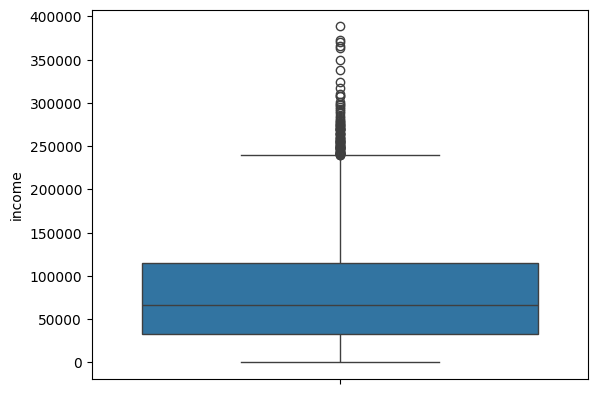

In [12]:
# Mendeteksi outliers secara visual dengan menggunakan boxplot dari seaborn dan menghapus outliers dengan menggunakan interquartiel range

import seaborn as sns
sns.boxplot(df2['income'])

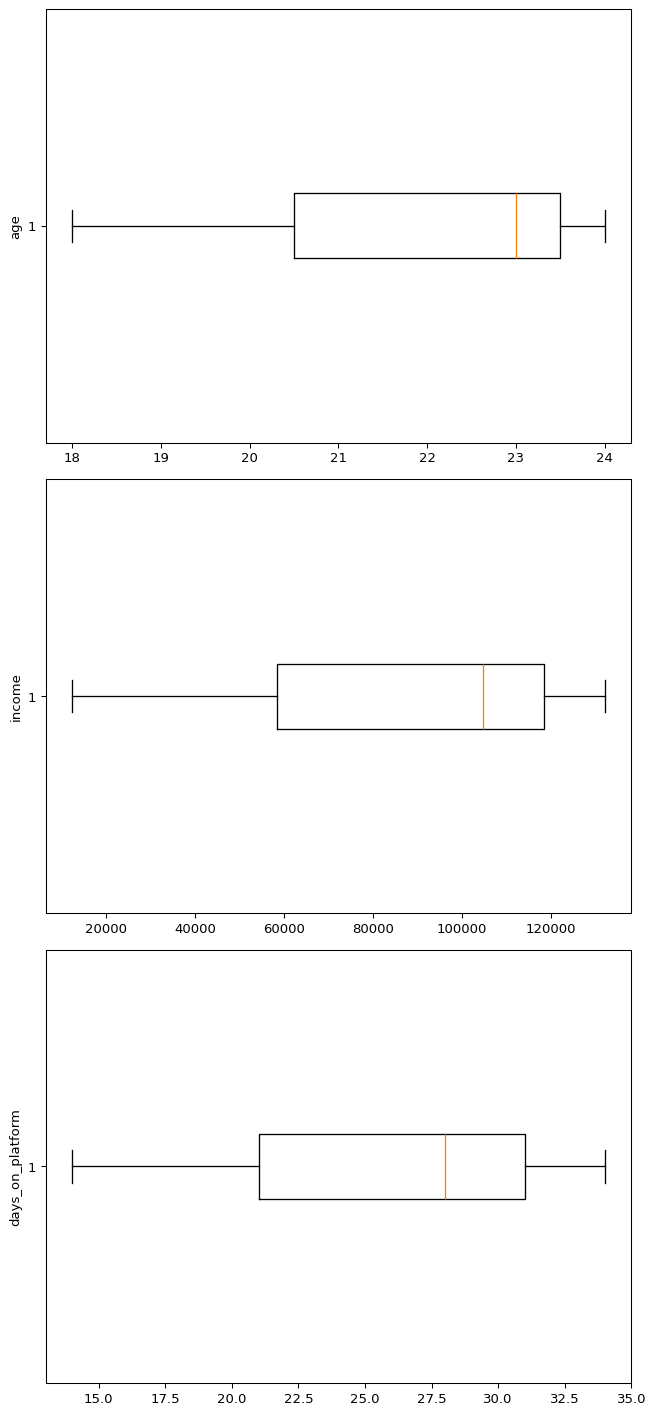

In [15]:
# Handling outliers dari dataset dengan memilih 3 kolom untuk dideteksi

import matplotlib.pyplot as plt
import pandas as pd

# Contoh DataFrame
df2 = pd.DataFrame({
    'age': [24.0, 18.0, 23.0],
    'income': [104723, 12315, 132181],
    'days_on_platform' : [14.0, 34.0, 28.0]
})

# Membuat daftar kolom yang ingin dianalisis
columns_to_plot = ['age', 'income', 'days_on_platform']

# Memastikan kolom ada di dataset
columns_to_plot = [col for col in columns_to_plot if col in df2.columns]

# Buat subplots berdasarkan jumlah kolom yang akan dianalisis
fig, axs = plt.subplots(len(columns_to_plot), 1, dpi=95, figsize=(7, 5 * len(columns_to_plot)))

# Jika hanya ada satu kolom, ubah `axs` menjadi list
if len(columns_to_plot) == 1:
    axs = [axs]

# Loop untuk membuat boxplot untuk setiap kolom
for i, col in enumerate(columns_to_plot):
    axs[i].boxplot(df2[col], vert=False)
    axs[i].set_ylabel(col)

# Tampilkan plot
plt.tight_layout()
plt.show()

### Plot hasil sesudah remove outlier

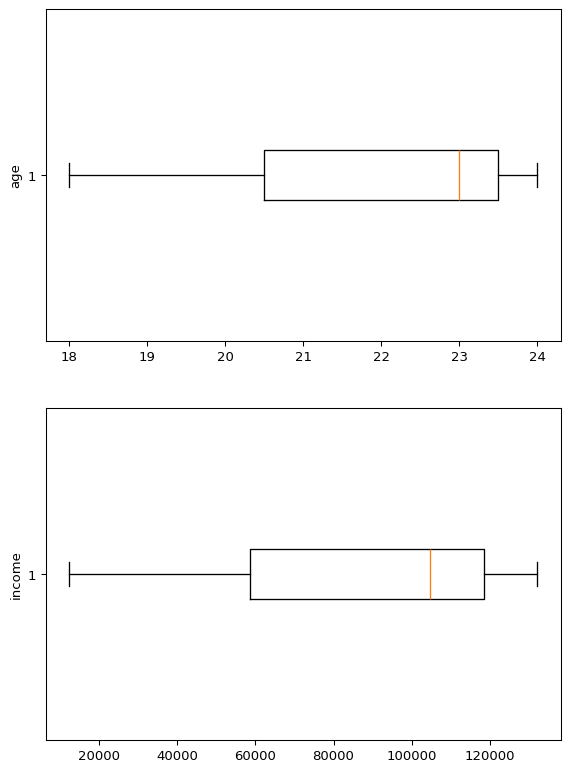

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Contoh DataFrame df2
data = {'age': [24.0, 18.0, 23.0],
        'income': [104723, 12315, 132181]}

df2 = pd.DataFrame(data)

def remove_outliers_sequentially(df, columns):
    df_cleaned = df.copy()
    for col in columns:
        q1, q3 = np.percentile(df_cleaned[col], [25, 75])
        iqr = q3 - q1
        lower_bound = q1 - (1.5 * iqr)
        upper_bound = q3 + (1.5 * iqr)
        df_cleaned = df_cleaned[(df_cleaned[col] >= lower_bound) & 
                                (df_cleaned[col] <= upper_bound)]
    return df_cleaned

# Terapkan fungsi untuk menghapus outliers dari "Height" dan "Weight"
clean_data = remove_outliers_sequentially(df2, ['age', 'income'])

# Plot boxplots setelah menghapus outliers
columns_to_plot = ['age', 'income']
fig, axs = plt.subplots(len(columns_to_plot), 1, dpi=95, figsize=(7, 5 * len(columns_to_plot)))

if len(columns_to_plot) == 1:
    axs = [axs]

for i, col in enumerate(columns_to_plot):
    axs[i].boxplot(clean_data[col], vert=False)
    axs[i].set_ylabel(col)

plt.show()

## e. Klasterisasi income dan days on platform menggunakan hierarchical clustering dan analisa hasilnya